In [1]:
import config_stp
import config_stp_esc
from stp_etc_esc import ExposureTimeSNRCalculatorESC as etsc  # import the package
from astropy import units as u
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [2]:
(97.5/6.5)*2.43

36.45

In [2]:
ESC = etsc.Observatory(telescope_name="Extrasolar Camera"
                      , telescope_diameter=6.5*u.m
                       , telescope_focal_len=97.5*u.m)
ESC.get_info()

***__name=Extrasolar Camera 

***__diameter_primary=6.5 m 

***__surf_area=33.18307240354219 m2 

***__lyot_stop_area=0 

***__num_mirrors=0 

***__focal_len=97.5 m 

***__f_num=15.0 

***__psf_diameter=None 

***__plate_scale=None 

***__gain=None 

***__dark_current=None 

***__read_noise=None 

***__num_pixels=None 

***__num_psf_pixels=None 

***__pixel_size=None 

***__sensor_area=None 

***__sensor_temp=None 

***__rawDH_contrast=None 

***__primary_filter=None 

***__sky_counts=0 

***__well_depth=None 

***__bandpass=SpectralElement
Model: Box1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
    amplitude  x_0    width 
    --------- ------ -------
          1.0 9000.0 10000.0 

***__precoron_bandpass=SpectralElement
Model: Box1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
    amplitude  x_0    width 
    --------- ------ -------
          1.0 9000.0 10000.0 

***__coron_bandpass=SpectralElement
Model: Box1D
Inputs: ('x',)
Outputs: ('y',)
Model se

In [3]:
preconfig_ESC = ESC.make_STP(subap='A',plot=False,telconfig='DEFAULT',escconfig='DEFAULT',telpath='DEFAULT',escpath='DEFAULT',contrast='spec')

In [4]:
ESC.get_info()

***__name=Extrasolar Camera 

***__diameter_primary=2.43 m 

***__surf_area=3.6811372856047075 m2 

***__lyot_stop_area=3.6811372856047075 m2 

***__num_mirrors=18 

***__focal_len=89.20237479771485 m 

***__f_num=36.70879621305138 

***__psf_diameter=56.130495227712295 um 

***__plate_scale=0.008694347003190635 

***__gain=0.261200000004368 electron / ct 

***__dark_current=0.0030703367499985944 electron / (pix s) 

***__read_noise=1.5221445224109558 electron(1/2) / pix(1/2) 

***__num_pixels=65536.0 pix 

***__num_psf_pixels=225.0 pix 

***__pixel_size=3.76 um / pix 

***__sensor_area=926521.7535999999 um2 

***__sensor_temp=0.0 deg_C 

***__rawDH_contrast=1e-08 

***__primary_filter=6329.999999999999 Angstrom 

***__sky_counts=0 

***__well_depth=16274.929434794496 electron / pix 

***__bandpass=SpectralElement
Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: [0] * [1] * [2] * [3] * [4] * [5] * [6] * [7] * [8] * [9] * [10] * [11] * [12] * [13] * [14]

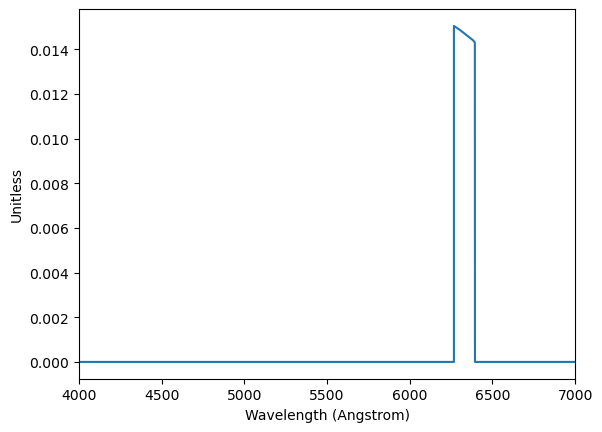

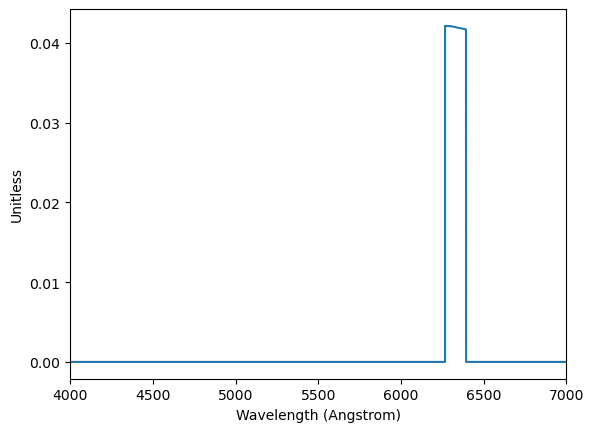

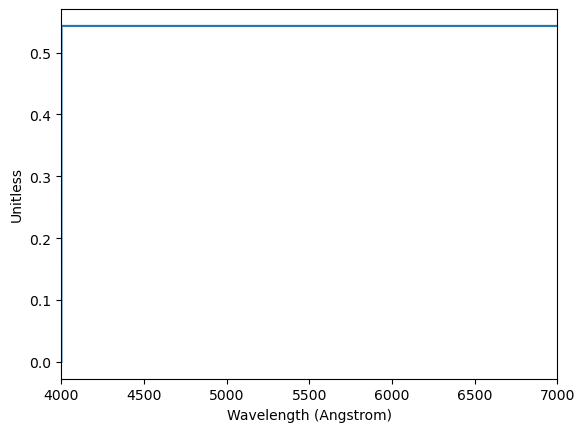

In [5]:
ESC.bandpass.plot(left=4000, right=7000)
ESC.precoron_bandpass.plot(left=4000,right=7000)
ESC.coron_bandpass.plot(left=4000,right=7000)

In [6]:
# Finding the peak throughput of the bandpasses
print(ESC.bandpass.tpeak())
print(ESC.precoron_bandpass.tpeak())
print(ESC.coron_bandpass.tpeak())

0.015051263857287727
0.04211917158110809
0.5431067337849071


In [7]:
psf_diameter, psf_min_num_pixels = ESC.calc_PSF()
print(psf_diameter.to('um'), '\n', psf_min_num_pixels)

56.130495227712295 um 
 225.0 pix


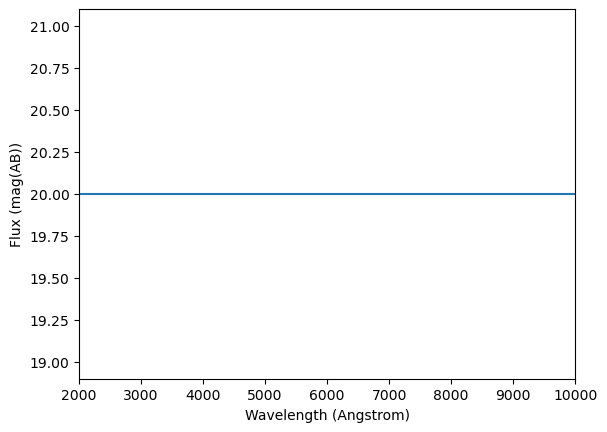

In [8]:
ESC.set_generic_source(1e-8,0,plot=True)

/Users/gudmundurstefansson/anaconda3/envs/py313/lib/python3.13/site-packages/config_stp/support_data/astrophysics/zodiacal_model_001.fits 

 SourceSpectrum at z=0.0
Model: Empirical1D
N_inputs: 1
N_outputs: 1
Parameters: 
  points: (array([  700.,   850.,  1000., ..., 24960., 24980., 25000.], dtype='>f8'),)
  lookup_table: [1.67137563e-18 2.02952755e-18 2.38767947e-18 ... 1.24186365e-07
 1.24139320e-07 1.24361335e-07]
  method: linear
  fill_value: nan
  bounds_error: False 




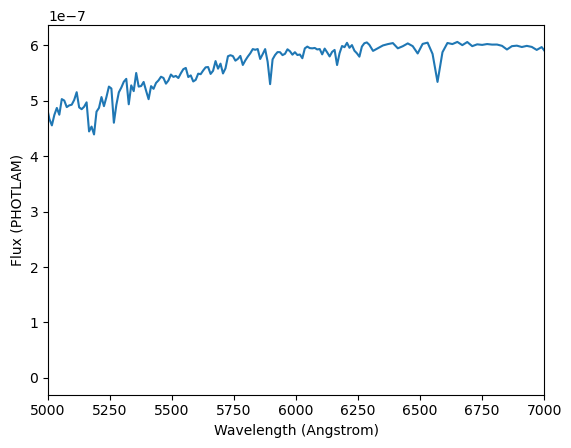

In [9]:
#zodi_model = stp_support_path / Path(stp_config['astrophysics']['zodi']['profile'])
ESC.set_background(background_file = None, plot=True) #None background file gives default background file from internal config
print(ESC.background_name, '\n'*2, ESC.background_spectrum, '\n'*2)

In [10]:
#ESC.make_observation(hoststarflux=hoststarflux, planetdeltamag=planetdeltamag,bg_flux=bg_flux,
#                     flux_units='vega', plot=False,exobg_flux=exobg_flux)
ESC.make_observation(hoststarflux=-0.353, planetdeltamag=20,bg_flux=22.5,
                     flux_units='vega', plot=False,exobg_flux=21)

(<Quantity 0.70379804 electron / s>,
 <Quantity 0.0001749 electron / s>,
 <Quantity 0.70379804 electron / s>)

In [11]:
ESC.get_info()

***__name=Extrasolar Camera 

***__diameter_primary=2.43 m 

***__surf_area=3.6811372856047075 m2 

***__lyot_stop_area=3.6811372856047075 m2 

***__num_mirrors=18 

***__focal_len=89.20237479771485 m 

***__f_num=36.70879621305138 

***__psf_diameter=56.130495227712295 um 

***__plate_scale=0.008694347003190635 

***__gain=0.261200000004368 electron / ct 

***__dark_current=0.0030703367499985944 electron / (pix s) 

***__read_noise=1.5221445224109558 electron(1/2) / pix(1/2) 

***__num_pixels=65536.0 pix 

***__num_psf_pixels=225.0 pix 

***__pixel_size=3.76 um / pix 

***__sensor_area=926521.7535999999 um2 

***__sensor_temp=0.0 deg_C 

***__rawDH_contrast=1e-08 

***__primary_filter=6329.999999999999 Angstrom 

***__sky_counts=0.00017490239405034512 electron / s 

***__well_depth=16274.929434794496 electron / pix 

***__bandpass=SpectralElement
Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: [0] * [1] * [2] * [3] * [4] * [5] * [6] * [7] * [8] * [9] 

In [12]:
ESC.calc_saturation_time()

<Quantity 2600001.95664473 s>

In [13]:
ESC.calc_SNR(600*u.s,10*u.s)

Source Counts 0.7037980430674727 electron / s
DC 0.6908257687496837 electron / s
RN 31278.473285926633 electron
Zodi 0.00017490239405034512 electron / s
Exozodi 0.0006353065010084852 electron / s
Speckles 0.7037980430674727 electron / s
M 0.07037980430674727 electron / s


2.279386813963883

In [14]:
ESC.calc_SNR??

Signature: ESC.calc_SNR(int_time, exp_time)
Docstring: <no docstring>
Source:   
    def calc_SNR(self, int_time, exp_time):
        # NOTE: Requires setting of source and/or background and performing 'make_observation'
        
        source_counts = self.source_counts


        sky_counts = self.sky_counts
        dark_current = self.dark_current
        readout_noise = self.read_noise
        num_sky_pix = self.num_pixels
        num_psf_pix = self.num_psf_pixels
        hoststar_counts = self.hoststar_counts
        speckle_counts = self.speckle_counts
        exozodi_counts = self.exozodi_counts
        M = speckle_counts*self.ppgain

        print('Source Counts',source_counts)
        print('DC',dark_current*num_psf_pix)
        print('RN',readout_noise*readout_noise*num_psf_pix*int_time/(exp_time))
        print('Zodi',sky_counts)
        print('Exozodi',exozodi_counts)
        print('Speckles',speckle_counts)
        print('M',M)
        
        # Need to give one the follow

In [ ]:
- How is SNR even defined?
- Can we change the radius?
- How does jitter impact things?
- Implement a flask application this weekend
- a